In [1]:
import random 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from pathlib import Path

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

2026-11-03 16:11:10.478719: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/Users/michelino/Desktop/RT-IoT2022-Anomaly-Detection/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
X_train = pd.read_csv("../data/processed/X_train.csv")
X_val = pd.read_csv("../data/processed/X_val.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

train_metadata = pd.read_csv(
    "../data/processed/train_metadata.csv"
)

val_metadata = pd.read_csv(
    "../data/processed/val_metadata.csv"
)

test_metadata = pd.read_csv(
    "../data/processed/test_metadata.csv"
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)


Training set: (7209, 92)
Validation set: (55356, 92)
Test set: (55357, 92)


In [3]:
y_val = (
    val_metadata["Label"] == "Anomaly"
).astype(int).to_numpy()

y_test = (
    test_metadata["Label"] == "Anomaly" 
).astype(int).to_numpy()

print("Validation labels:")
print(pd.Series(y_val).value_counts())

print("\nTest labels:")
print(pd.Series(y_test).value_counts())

Validation labels:
1    52953
0     2403
Name: count, dtype: int64

Test labels:
1    52954
0     2403
Name: count, dtype: int64


In [4]:
X_train_np = X_train.to_numpy(dtype=np.float32)
X_val_np = X_val.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)

print("X_train:", X_train_np.shape, X_train_np.dtype)
print("X_val:", X_val_np.shape, X_val_np.dtype)
print("X_test:", X_test_np.shape, X_test_np.dtype)

X_train: (7209, 92) float32
X_val: (55356, 92) float32
X_test: (55357, 92) float32


In [5]:
print(
    "NaN in training:",
    np.isnan(X_train_np).sum()
)

print(
    "NaN in validation:",
    np.isnan(X_val_np).sum()
)

print(
    "NaN in test:",
    np.isnan(X_test_np).sum()
)

print(
    "Infinite values in training:",
    np.isinf(X_train_np).sum()
)

print(
    "Infinite values in validation:",
    np.isinf(X_val_np).sum()
)

print(
    "Infinite values in test:",
    np.isinf(X_test_np).sum()
)

NaN in training: 0
NaN in validation: 0
NaN in test: 0
Infinite values in training: 0
Infinite values in validation: 0
Infinite values in test: 0


In [6]:
input_dim = X_train_np.shape[1]
baseline_latent_dim = 16

baseline_model = keras.Sequential(
    [
        layers.Input(shape=(input_dim,)),

        layers.Dense(
            64,
            activation="relu"
        ),

        layers.Dense(
            32,
            activation="relu"
        ),

        layers.Dense(
            baseline_latent_dim,
            activation="relu",
            name="latent_space"
        ),

        layers.Dense(
            32,
            activation="relu"
        ),

        layers.Dense(
            64,
            activation="relu"
        ),

        layers.Dense(
            input_dim,
            activation="linear"
        )
    ],
    name="baseline_autoencoder"
)

baseline_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mae"
)

baseline_model.summary()

Model: "baseline_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         5,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 92)             │         5,980 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,196 (67.17 KB)

 Trainable params: 17,196 (67.17 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience = 8,
    min_delta = 1e-5,
    restore_best_weights = True
)

In [8]:
history = baseline_model.fit(
    X_train_np,
    X_train_np,
    
    epochs = 100,
    batch_size = 128,
    
    validation_split = 0.15,
    
    shuffle = True,
    
    callbacks = [
        early_stopping
    ],
    
    verbose = 1
)

Epoch 1/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.3761 - val_loss: 0.2792
Epoch 2/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2289 - val_loss: 0.1170
Epoch 3/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1088 - val_loss: 0.0907
Epoch 4/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0866 - val_loss: 0.0804
Epoch 5/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0778 - val_loss: 0.0778
Epoch 6/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0754 - val_loss: 0.0769
Epoch 7/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0745 - val_loss: 0.0765
Epoch 8/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0738 - val_loss: 0.0741
Epoch 9/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0700 - val_loss: 0.0595
Epoch 10/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0559 - val_loss: 0.0522
Epoch 11/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0517 - val_loss: 0.0505
Epoch 12/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss:

In [9]:
best_epoch = np.argmin(
    history.history["val_loss"]
)

print(
    "Epochs trained:",
    len(history.history["loss"])
)

print(
    "Last recorded training loss:",
    history.history["loss"][-1]
)

print(
    "Best validation loss:",
    history.history["val_loss"][best_epoch]
)

print(
    "Best epoch:",
    best_epoch + 1
)

Epochs trained: 100
Last recorded training loss: 0.03982454538345337
Best validation loss: 0.04010024294257164
Best epoch: 99


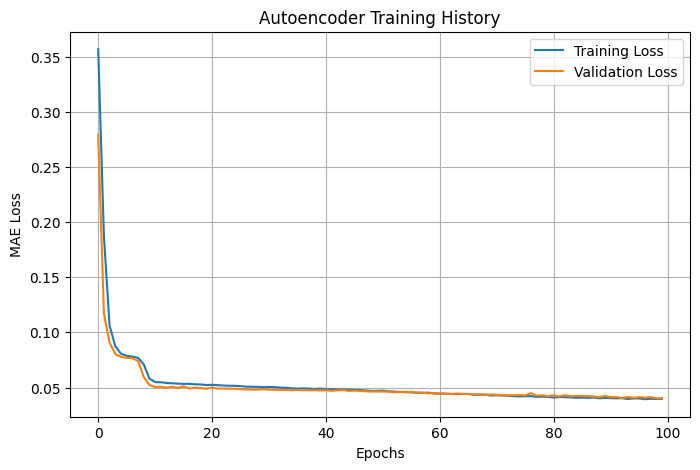

In [10]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label = "Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label = "Validation Loss"
)
plt.xlabel("Epochs")
plt.ylabel("MAE Loss")
plt.title("Autoencoder Training History")

plt.legend()
plt.grid()

plt.show()

In [11]:
train_reconstructed = baseline_model.predict(
    X_train_np,
    batch_size = 256,
    verbose = 0
)

val_reconstructed = baseline_model.predict(
    X_val_np,
    batch_size = 256,
    verbose = 0
)

train_errors = np.mean(
    np.abs(
        X_train_np - train_reconstructed
    ),
    axis = 1
)

val_errors = np.mean(
    np.abs(
        X_val_np - val_reconstructed
    ),
    axis = 1
)

print(
    "Training reconstruction errors:",
    train_errors.shape
)

print(
    "Validation reconstruction errors:",
    val_errors.shape
)

Training reconstruction errors: (7209,)
Validation reconstruction errors: (55356,)


In [12]:
val_normal_errors = val_errors[
    y_val == 0
]

val_anomaly_errors = val_errors[
    y_val == 1
]

error_summary = pd.DataFrame(
   {
       "Training normal": [
           np.mean(train_errors),
           np.median(train_errors),
           np.std(train_errors),
           np.percentile(train_errors, 95),
           np.percentile(train_errors, 99),
           np.max(train_errors)
       ],
       
       "Validation normal": [
           np.mean(val_normal_errors),
           np.median(val_normal_errors),
           np.std(val_normal_errors),
           np.percentile(val_normal_errors, 95),
           np.percentile(val_normal_errors, 99),
           np.max(val_normal_errors)
       ],
       
       "Validation anomaly": [
           np.mean(val_anomaly_errors),
           np.median(val_anomaly_errors),
           np.std(val_anomaly_errors),
           np.percentile(val_anomaly_errors, 95),
           np.percentile(val_anomaly_errors, 99),
           np.max(val_anomaly_errors)
       ]
   },
   
   index = [
       "mean",
       "median",
       "std",
       "p95",
       "p99",
       "max"
   ]
)

error_summary

,Training normal,Validation normal,Validation anomaly
mean,0.039521,0.037424,91.079422
median,0.016851,0.016592,57.545738
std,0.116957,0.111690,86.741516
p95,0.118307,0.091571,244.619690
p99,0.534146,0.575662,244.634598
max,2.730461,2.015277,244.637314


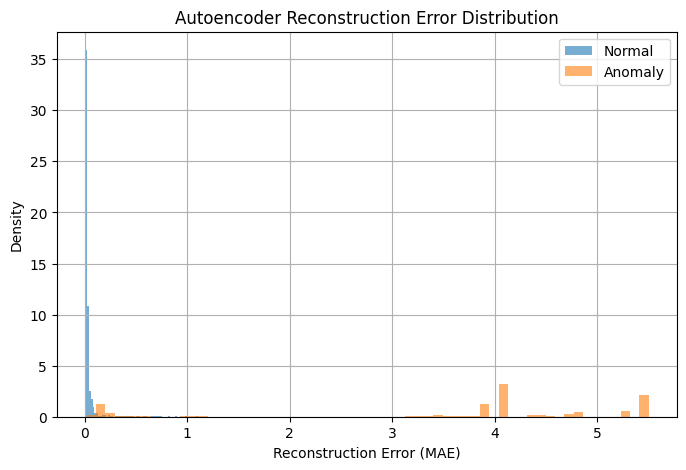

In [13]:
plt.figure(figsize=(8,5))

plt.hist(
    np.log1p(val_normal_errors),
    bins = 60,
    density = True,
    alpha = 0.6,
    label = "Normal"
)

plt.hist(
    np.log1p(val_anomaly_errors),
    bins = 60,
    density = True,
    alpha = 0.6,
    label = "Anomaly"
)

plt.xlabel("Reconstruction Error (MAE)")
plt.ylabel("Density")

plt.title(
    "Autoencoder Reconstruction Error Distribution"
)

plt.legend()
plt.grid()

plt.show()

In [14]:
baseline_threshold = np.max(
    train_errors
)

print(
    "Baseline threshold:",
    baseline_threshold
)

baseline_predictions = (
    val_errors > baseline_threshold
).astype(int)

baseline_cm = confusion_matrix(
    y_val,
    baseline_predictions
)

print("Confusion Matrix:")
print(baseline_cm)

tn, fp, fn, tp = baseline_cm.ravel()

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

baseline_accuracy = accuracy_score(
    y_val,
    baseline_predictions
)

baseline_precision = precision_score(
    y_val,
    baseline_predictions
)

baseline_recall = recall_score(
    y_val,
    baseline_predictions
)

baseline_f1 = f1_score(
    y_val,
    baseline_predictions
)

baseline_balanced_accuracy = (
    balanced_accuracy_score(
        y_val,
        baseline_predictions
    )
)

baseline_fpr = fp / (fp + tn)

print(
    "Accuracy:",
    baseline_accuracy
)

print(
    "Precision:",
    baseline_precision
)

print(
    "Recall:",
    baseline_recall
)

print(
    "F1-score:",
    baseline_f1
)

print(
    "Balanced Accuracy:",
    baseline_balanced_accuracy
)

print(
    "False Positive Rate:",
    baseline_fpr
)

baseline_roc_auc = roc_auc_score(
    y_val,
    val_errors
)

baseline_pr_auc = (
    average_precision_score(
        y_val,
        val_errors
    )
)

print(
    "ROC-AUC:",
    baseline_roc_auc
)

print(
    "PR-AUC:",
    baseline_pr_auc
)

Baseline threshold: 2.7304606
Confusion Matrix:
[[ 2403     0]
 [10447 42506]]

True Negatives: 2403
False Positives: 0
False Negatives: 10447
True Positives: 42506
Accuracy: 0.8112761037647229
Precision: 1.0
Recall: 0.8027118388004457
F1-score: 0.8905603452791251
Balanced Accuracy: 0.9013559194002229
False Positive Rate: 0.0
ROC-AUC: 0.9938954887396553
PR-AUC: 0.9997019097577183


In [15]:
thresholds = {
    "P90": np.percentile(train_errors, 90),
    "P95": np.percentile(train_errors, 95),
    "P97.5": np.percentile(train_errors, 97.5),
    "P99": np.percentile(train_errors, 99),
    "P99.5": np.percentile(train_errors, 99.5),
    "MAX": np.max(train_errors)
}

for name, value in thresholds.items():
    print(name, ":", value)

P90 : 0.06199964806437491
P95 : 0.11830725073814387
P97.5 : 0.2599680602550507
P99 : 0.5341463232040409
P99.5 : 0.7741973614692689
MAX : 2.7304606


In [16]:
threshold_results = []

for threshold_name, threshold in thresholds.items():
    predictions =(
        val_errors > threshold
    ).astype(int)
    
    cm = confusion_matrix(
      y_val,
      predictions
    )

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(
      y_val,
      predictions
    )

    precision = precision_score(
      y_val,
      predictions,
      zero_division = 0
    )

    recall = recall_score(
      y_val,
      predictions
    )

    f1 = f1_score(
      y_val,
      predictions
    )

    balanced_accuracy = balanced_accuracy_score(
      y_val,
      predictions
    )

    fpr = fp / (fp + tn)

    threshold_results.append({
      "threshold_name": threshold_name,
      "threshold": threshold,
      "accuracy": accuracy,
      "precision": precision,
      "recall": recall,
      "f1": f1,
      "balanced_accuracy": balanced_accuracy,
      "fpr": fpr
    })

threshold_df = pd.DataFrame(
  threshold_results
)

threshold_df

,threshold_name,threshold,accuracy,precision,recall,f1,balanced_accuracy,fpr
0,P90,0.062000,0.991220,0.995898,0.994920,0.995409,0.952308,0.090304
1,P95,0.118307,0.981140,0.998196,0.982060,0.990062,0.971471,0.039118
2,P97.5,0.259968,0.858570,0.998762,0.853209,0.920266,0.914953,0.023304
3,P99,0.534146,0.832484,0.999383,0.825392,0.904093,0.907078,0.011236
4,P99.5,0.774197,0.825782,0.999654,0.818159,0.899846,0.905959,0.006242
5,MAX,2.730461,0.811276,1.000000,0.802712,0.890560,0.901356,0.000000


In [17]:
threshold_df = threshold_df.sort_values(
    by = [
        "balanced_accuracy",
        "fpr",
        "recall"
    ],
    
    ascending = [
        False,
        True,
        False
    ]
).reset_index(drop = True)

threshold_df

,threshold_name,threshold,accuracy,precision,recall,f1,balanced_accuracy,fpr
0,P95,0.118307,0.981140,0.998196,0.982060,0.990062,0.971471,0.039118
1,P90,0.062000,0.991220,0.995898,0.994920,0.995409,0.952308,0.090304
2,P97.5,0.259968,0.858570,0.998762,0.853209,0.920266,0.914953,0.023304
3,P99,0.534146,0.832484,0.999383,0.825392,0.904093,0.907078,0.011236
4,P99.5,0.774197,0.825782,0.999654,0.818159,0.899846,0.905959,0.006242
5,MAX,2.730461,0.811276,1.000000,0.802712,0.890560,0.901356,0.000000


In [18]:
best_threshold_result = threshold_df.iloc[0]

best_threshold_name = best_threshold_result[
    "threshold_name"
]

best_threshold = best_threshold_result[
    "threshold"
]

print(
    "Best threshold:",
    best_threshold_name
)

print(
    "Threshold value:",
    best_threshold
)

print(
    "Balanced Accuracy:",
    best_threshold_result[
        "balanced_accuracy"
    ]
)

print(
    "Recall:",
    best_threshold_result[
        "recall"
    ]
)

print(
    "False Positive Rate:",
    best_threshold_result[
        "fpr"
    ]
) 

Best threshold: P95
Threshold value: 0.11830725073814387
Balanced Accuracy: 0.9714708963992355
Recall: 0.982059562253319
False Positive Rate: 0.03911776945484811


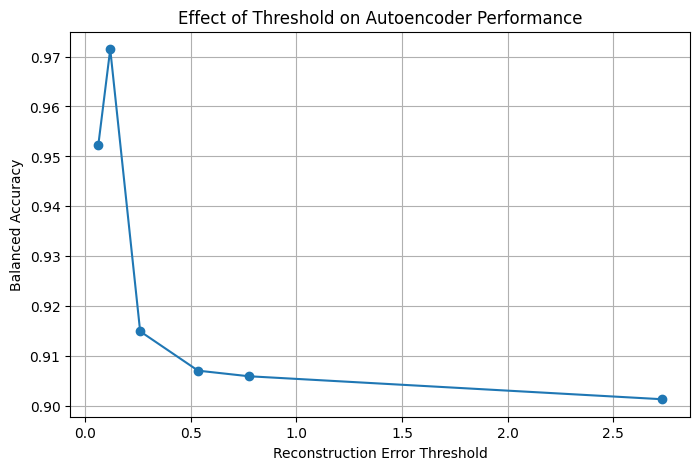

In [19]:
plot_df = threshold_df.sort_values(
    "threshold"
)

plt.figure(figsize=(8, 5))

plt.plot(
    plot_df["threshold"],
    plot_df["balanced_accuracy"],
    marker = "o"
)

plt.xlabel(
    "Reconstruction Error Threshold"
)

plt.ylabel(
    "Balanced Accuracy"
)

plt.title(
    "Effect of Threshold on Autoencoder Performance"
)

plt.grid()
plt.show()

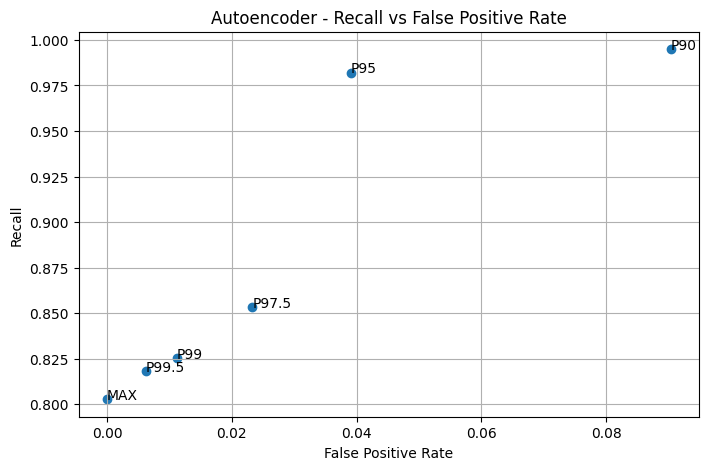

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    threshold_df["fpr"],
    threshold_df["recall"]
)

for _, row in threshold_df.iterrows():
    
    plt.annotate(
        row["threshold_name"],
        (
            row["fpr"],
            row["recall"]
        )
    )
    
plt.xlabel(
    "False Positive Rate"
)   

plt.ylabel(
    "Recall"
) 

plt.title(
    "Autoencoder - Recall vs False Positive Rate"
)

plt.grid()
plt.show()

In [21]:
latent_dimensions = [
    8,
    16,
    32
]

def build_autoencoder(
    input_dim,
    latent_dim
):
    
    model = keras.Sequential(
        [
            layers.Input(
                shape=(input_dim,)
            ),
            
            layers.Dense(
                64,
                activation = "relu"
            ),
            
            layers.Dense(
                32,
                activation = "relu",
               
            ),
            
            layers.Dense(
                latent_dim,
                activation = "relu",
                name = "latent_space"
            ),
            
            layers.Dense(
                32,
                activation = "relu"
            ),
            
            layers.Dense(
                64,
                activation = "relu"
            ),
            
            layers.Dense(
                input_dim,
                activation = "linear"
            )
        ]
    )
    
    model.compile(
        optimizer = keras.optimizers.Adam(
            learning_rate = 0.001
        ),
        loss = "mae"
    )
    
    return model

latent_results = []

input_dim = X_train_np.shape[1]

for latent_dim in latent_dimensions:
    
    print(
        "\nTesting latent dimension =",
        latent_dim
    )
    
    keras.backend.clear_session()
    
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)
    
    model = build_autoencoder(
        input_dim,
        latent_dim
    )
    
    early_stopping = keras.callbacks.EarlyStopping(
        monitor = "val_loss",
        patience = 8,
        min_delta = 1e-5,
        restore_best_weights=True
    )
    
    history_latent = model.fit(
        X_train_np,
        X_train_np,
        
        epochs = 100,
        batch_size = 128,
        
        validation_split = 0.15,
        
        shuffle = True,
        
        callbacks = [
            early_stopping
        ],
        
        verbose = 0
    )
    
    train_reconstructed = model.predict(
        X_train_np,
        batch_size = 256,
        verbose = 0
    )
    
    val_reconstructed = model.predict(
        X_val_np,
        batch_size = 256,
        verbose = 0
    )
    
    latent_train_errors = np.mean(
        np.abs(
            X_train_np - train_reconstructed
        ),
        axis = 1
    )
    
    latent_val_errors = np.mean(
        np.abs(
            X_val_np - val_reconstructed
        ),
        axis = 1
    )
    
    latent_thresholds = {
        
        "P90": np.percentile(
            latent_train_errors,
            90
        ),
        
        "P95": np.percentile(
            latent_train_errors,
            95
        ),
        
        "P97.5": np.percentile(
            latent_train_errors,
            97.5
        ),
        
        "P99": np.percentile(
            latent_train_errors,
            99
        ),
        
        "P99.5": np.percentile(
            latent_train_errors,
            99.5
        ),
        
        "MAX": np.max(
            latent_train_errors,
        ),  
    }
    
    current_results = []
    
    for threshold_name, threshold in latent_thresholds.items():
        
        predictions = (
            latent_val_errors >
            threshold
        ).astype(int)
        
        cm = confusion_matrix(
            y_val,
            predictions
        )
        
        tn, fp, fn, tp = cm.ravel()
        
        balanced_accuracy = (
            balanced_accuracy_score(
                y_val,
                predictions
            )
        )
        
        precision = precision_score(
            y_val,
            predictions,
            zero_division = 0
        )
        
        recall = recall_score(
            y_val,
            predictions
        )
        
        f1 = f1_score(
            y_val,
            predictions
        )
        
        fpr = fp / (
            fp + tn
        )
        
        current_results.append({
            "latent_dim": latent_dim,
            "threshold_name": threshold_name,
            "threshold": threshold,
            "balanced_accuracy": balanced_accuracy,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "fpr": fpr
        })
    
    current_df  = pd.DataFrame(
        current_results
    )    
    
    current_df = current_df.sort_values(
        by = [
            "balanced_accuracy",
            "fpr",
            "recall"
        ],
        
        ascending = [
            False,
            True,
            False
        ] 
    )
    
    best_current = current_df.iloc[0]
    
    latent_results.append(
        best_current.to_dict()
    )
    
    print(
        "Best threshold:",
        best_current[
            "threshold_name"
        ]
    )
    
    print(
        "Balanced Accuracy:",
        best_current[
            "balanced_accuracy"
        ]
    )
    
latent_df = pd.DataFrame(
    latent_results
)
    
latent_df = latent_df.sort_values(
    by = [
        "balanced_accuracy",
        "fpr",
        "recall"
    ],
         
    ascending = [
        False,
        True,
        False
    ]
).reset_index(drop = True)
    
latent_df


Testing latent dimension = 8
Best threshold: P95
Balanced Accuracy: 0.966292736028862

Testing latent dimension = 16
Best threshold: P95
Balanced Accuracy: 0.9714708963992355

Testing latent dimension = 32
Best threshold: P95
Balanced Accuracy: 0.9734355859304059


,latent_dim,threshold_name,threshold,balanced_accuracy,precision,recall,f1,fpr
0,32,P95,0.117436,0.973436,0.998240,0.985157,0.991655,0.038285
1,16,P95,0.118307,0.971471,0.998196,0.982060,0.990062,0.039118
2,8,P95,0.136132,0.966293,0.997973,0.976281,0.987008,0.043695


In [22]:
best_config = latent_df.iloc[0]

best_latent_dim = int(
    best_config[
        "latent_dim"
    ]
)

selected_threshold_name = (
    best_config[
        "threshold_name"
    ]
)

print(
    "Selected latent dimension:",
    best_latent_dim
)

print(
    "Selected threshold type:",
    selected_threshold_name
)

print(
    "Validation Balanced Accuracy:",
    best_config[
        "balanced_accuracy"
    ]
)

print(
    "Validation Recall:",
    best_config[
        "recall"
    ]
)

print(
    "Validation FPR:",
    best_config[
        "fpr"
    ]
)

Selected latent dimension: 32
Selected threshold type: P95
Validation Balanced Accuracy: 0.9734355859304059
Validation Recall: 0.9851566483485354
Validation FPR: 0.03828547648772368


In [23]:
keras.backend.clear_session()

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

final_model = build_autoencoder(
    input_dim,
    best_latent_dim
)

final_early_stopping = (
    keras.callbacks.EarlyStopping(
        monitor = "val_loss",
        patience = 8,
        min_delta = 1e-5,
        restore_best_weights = True
    )
)

final_history = final_model.fit(
    X_train_np,
    X_train_np,
    
    epochs = 100,
    batch_size = 128,

    validation_split = 0.15,

    shuffle = True,

    callbacks = [
    final_early_stopping
    ],

    verbose = 1
)

final_train_reconstructed = (
    final_model.predict(
        X_train_np,
        batch_size = 256,
        verbose = 0
    )
)

final_train_errors = np.mean(
    np.abs(
        X_train_np - final_train_reconstructed
    ),
    axis = 1
)

final_thresholds = {
    "P90": np.percentile(
        final_train_errors,
        90
    ),
    
    "P95": np.percentile(
        final_train_errors,
        95
    ),
    
    "P97.5": np.percentile(
        final_train_errors,
        97.5
    ),
    
    "P99": np.percentile(
        final_train_errors,
        99
    ),
    
    "P99.5": np.percentile(
        final_train_errors,
        99.5
    ),
    
    "MAX": np.max(
        final_train_errors
    )
}

final_threshold = final_thresholds[
    selected_threshold_name
]

print(
    "Final latent dimension:",
    best_latent_dim
)

print(
    "Final threshold type:",
    selected_threshold_name
)

print(
    "Final threshold:",
    final_threshold
)

Epoch 1/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.3748 - val_loss: 0.2557
Epoch 2/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2285 - val_loss: 0.1286
Epoch 3/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1137 - val_loss: 0.0837
Epoch 4/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0784 - val_loss: 0.0713
Epoch 5/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0647 - val_loss: 0.0550
Epoch 6/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0545 - val_loss: 0.0525
Epoch 7/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0527 - val_loss: 0.0512
Epoch 8/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0516 - val_loss: 0.0520
Epoch 9/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0516 - val_loss: 0.0514
Epoch 10/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0511 - val_loss: 0.0512
Epoch 11/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0510 - val_loss: 0.0507
Epoch 12/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0

In [24]:
test_reconstructed = final_model.predict(
    X_test_np,
    batch_size = 256,
    verbose = 0
)

test_errors = np.mean(
    np.abs(
        X_test_np - test_reconstructed
    ),
    axis = 1
)

test_predictions = (
    test_errors > 
    final_threshold
).astype(int)

In [25]:
test_cm = confusion_matrix(
    y_test,
    test_predictions
)

tn, fp, fn, tp = test_cm.ravel()

print(
    "Confusion Matrix:"
)

print(
    test_cm
)

print(
    "\nTrue Negatives:",
    tn
)

print(
    "False Positives:",
    fp
)

print(
    "False Negatives:",
    fn
)

print(
    "True Positives:",
    tp
)

Confusion Matrix:
[[ 2280   123]
 [  765 52189]]

True Negatives: 2280
False Positives: 123
False Negatives: 765
True Positives: 52189


In [26]:
test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

test_precision = precision_score(
    y_test,
    test_predictions
)

test_recall = recall_score(
    y_test,
    test_predictions
)

test_f1 = f1_score(
    y_test,
    test_predictions
)

test_balanced_accuracy = (
    balanced_accuracy_score(
        y_test,
        test_predictions
    )
)

test_fpr = fp / (
    fp + tn
)

test_roc_auc = roc_auc_score(
    y_test,
    test_errors
)

test_pr_auc = (
    average_precision_score(
        y_test,
        test_errors
    )
)

print(
    "Accuracy:",
    test_accuracy
)

print(
    "Precision:",
    test_precision
)

print(
    "Recall:",
    test_recall
)

print(
    "F1-score:",
    test_f1
)

print(
    "Balanced Accuracy:",
    test_balanced_accuracy
)

print(
    "False Positive Rate:",
    test_fpr
)

print(
    "ROC-AUC:",
    test_roc_auc
)

print(
    "PR-AUC:",
    test_pr_auc
)

Accuracy: 0.9839586682804343
Precision: 0.9976487230463373
Recall: 0.9855534992635118
F1-score: 0.9915642277658503
Balanced Accuracy: 0.9671837408926798
False Positive Rate: 0.05118601747815231
ROC-AUC: 0.9928677409083342
PR-AUC: 0.9996502830773137


In [27]:
attack_analysis = (
    test_metadata.copy()
)

attack_analysis[
    "Prediction"
] = test_predictions

attack_analysis = (
    attack_analysis[
        attack_analysis[
            "Label"
        ] == "Anomaly"
    ]
)

attack_detection = (
    attack_analysis
    .groupby(
        "Attack_type"
    )["Prediction"]
    .agg(
        [
            "count",
            "sum"
        ]
    )
)

attack_detection[
    "detection_rate"
] = (
    attack_detection["sum"] /
    attack_detection["count"]
)

attack_detection

,count,sum,detection_rate
Attack_type,,,
ARP_poisioning,3813,3056,0.801469
DDOS_Slowloris,266,266,1.000000
DOS_SYN_Hping,45045,45045,1.000000
Metasploit_Brute_Force_SSH,18,17,0.944444
NMAP_FIN_SCAN,14,13,0.928571
NMAP_OS_DETECTION,1000,1000,1.000000
NMAP_TCP_scan,501,501,1.000000
NMAP_UDP_SCAN,1292,1286,0.995356
NMAP_XMAS_TREE_SCAN,1005,1005,1.000000


In [28]:
Path(
    "../results/tables"
).mkdir(
    parents = True,
    exist_ok = True
)

Path(
    "../results/models"
).mkdir(
    parents = True,
    exist_ok = True
)

threshold_df.to_csv(
    "../results/tables/autoencoder_threshold_results.csv",
    index = False
)

latent_df.to_csv(
    "../results/tables/autoencoder_latent_results.csv",
    index = False
)

attack_detection.to_csv(
    "../results/tables/autoencoder_attack_detection.csv"
)

In [29]:
final_metrics = pd.DataFrame(
    {
        "metric": [
            "accuracy",
            "precision",
            "recall",
            "f1",
            "balanced_accuracy",
            "fpr",
            "roc_auc",
            "pr_auc"
        ],
        
        "value": [
            test_accuracy,
            test_precision,
            test_recall,
            test_f1,
            test_balanced_accuracy,
            test_fpr,
            test_roc_auc,
            test_pr_auc
        ]
    }
)

final_metrics

final_metrics.to_csv(
    "../results/tables/autoencoder_final_metrics.csv",
    index = False
)

In [30]:
final_model.save(
    "../results/models/autoencoder_final.keras"
)

final_configuration = pd.DataFrame(
    [{
      "latent_dimension": best_latent_dim,
      "threshold_type": selected_threshold_name,
      "threshold_value": final_threshold,
      "batch_size": 128,
      "learning_rate": 0.001,
      "loss": "MAE"
    }]
)

final_configuration

final_configuration.to_csv(
    "../results/tables/autoencoder_configuration.csv",
    index = False
)